## Import Libraries

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Import the Data

In [10]:
training_data = pd.read_csv('./Data/train.csv')
testing_data  = pd.read_csv('./Data/test.csv')
# We have all data to apply same transform or all new columns to the train and test data set
all_data = pd.concat([training_data, testing_data], keys=['train', 'test']).reset_index(0).rename(columns={'level_0': 'train/test'})
all_data.head()

,train/test,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,train,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,train,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,train,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,train,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,train,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Data Exploration 

In [11]:
# We fouce on Explore the Training data 
training_data.info()
# We see we have missing values in Cabin , Age , Embarked 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [12]:
training_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [13]:
training_data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [14]:
# We spilt the Numerical and Categorical Data 
df_Num = training_data[['Age', 'SibSp','Parch','Fare']]
df_Cat = training_data[['Survived', 'Pclass','Sex','Ticket','Cabin', 'Embarked']]

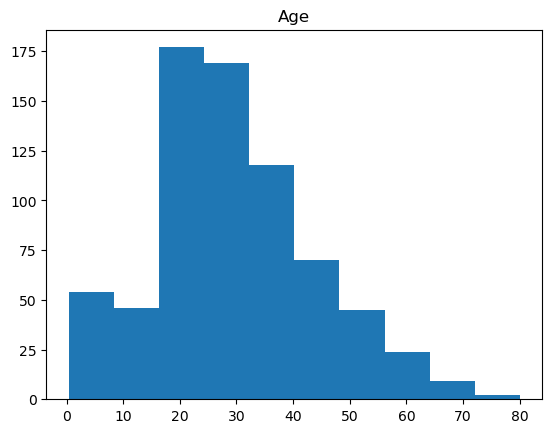

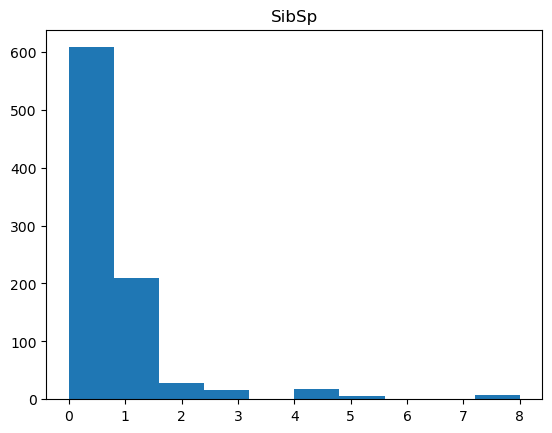

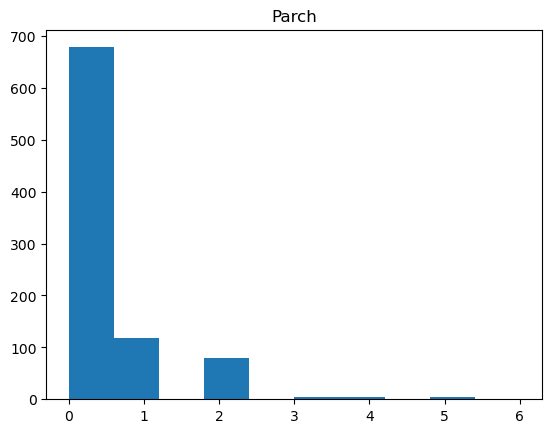

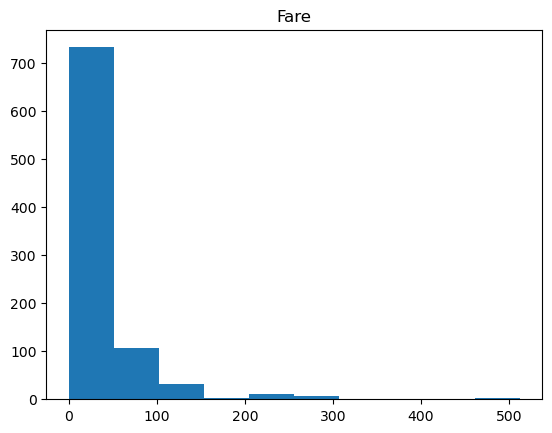

In [15]:
# Plot the Distribution of The Numerical Data
for i in df_Num.columns:
    plt.hist(df_Num[i])
    plt.title(i)
    plt.show()
# We see that the Age is the Only Column that is Normally Distribution , We need to transform the other columns

            Age     SibSp     Parch      Fare
Age    1.000000 -0.308247 -0.189119  0.096067
SibSp -0.308247  1.000000  0.414838  0.159651
Parch -0.189119  0.414838  1.000000  0.216225
Fare   0.096067  0.159651  0.216225  1.000000


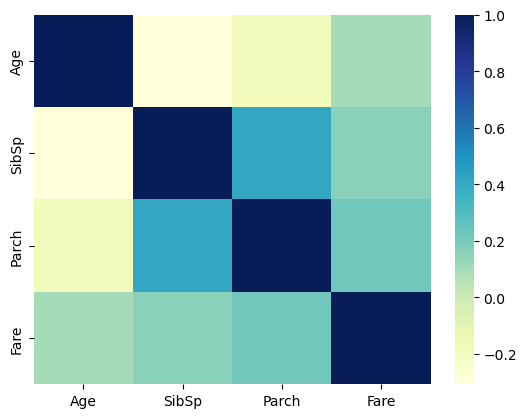

In [16]:
# We check the multicollinearity
print(df_Num.corr())
sns.heatmap(df_Num.corr(),cmap='YlGnBu')
plt.show()

In [17]:
pd.pivot_table(training_data, index = 'Survived', values = ['Age','SibSp','Parch','Fare'])

,Age,Fare,Parch,SibSp
Survived,,,,
0,30.626179,22.117887,0.329690,0.553734
1,28.343690,48.395408,0.464912,0.473684


In [47]:
print(pd.pivot_table(training_data, index = 'Survived', columns = 'Pclass', values = 'Ticket' ,aggfunc ='count'))
print()
print(pd.pivot_table(training_data, index = 'Survived', columns = 'Sex', values = 'Ticket' ,aggfunc ='count'))
print()
print(pd.pivot_table(training_data, index = 'Survived', columns = 'Embarked', values = 'Ticket' ,aggfunc ='count'))

Pclass      1   2    3
Survived              
0          80  97  372
1         136  87  119

Sex       female  male
Survived              
0             81   468
1            233   109

Embarked   C   Q    S
Survived             
0         75  47  427
1         93  30  217


In [39]:
training_data[['Pclass','Survived']].groupby(['Pclass']).mean()

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


## Feature Engineering 

In [178]:
# Cabins       - Did the letter of cabin or the person that have multiple cabins effect the survived ?
# Person title - Did the Person title (Mr,Mrs,Dr,Sir...etc) effect the survived ?

In [167]:
# First Canbins get the number of cabins 
num_Cabins = training_data.Cabin.apply(lambda x:0 if pd.isna(x) else len(x.split(' ')))
print(num_Cabins.value_counts())
training_data['num_Cabins'] = num_Cabins

Cabin
0    687
1    180
2     16
3      6
4      2
Name: count, dtype: int64


In [170]:
pd.pivot_table(training_data,index='Survived',columns='num_Cabins',values='Ticket',aggfunc='count')

num_Cabins,0,1,2,3,4
Survived,,,,,
0,481.0,58.0,7.0,3.0,NaN
1,206.0,122.0,9.0,3.0,2.0


In [176]:
# The go with Cabin letters 
Cabin_letter = training_data.Cabin.apply(lambda x:str(x)[0])
Cabin_letter.value_counts()
training_data['Cabin_letter'] = Cabin_letter

In [177]:
pd.pivot_table(training_data,index='Survived',columns='Cabin_letter',values='Ticket',aggfunc='count')

Cabin_letter,A,B,C,D,E,F,G,T,n
Survived,,,,,,,,,
0,8.0,12.0,24.0,8.0,8.0,5.0,2.0,1.0,481.0
1,7.0,35.0,35.0,25.0,24.0,8.0,2.0,NaN,206.0


In [194]:
# Then the name Titles 
name_title = training_data.Name.apply(lambda x:str(x.split(',')[1].split('.')[0]))
print(name_title.value_counts())
training_data['name_title'] = name_title

Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64


In [195]:
training_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,num_Cabins,Cabin_letter,name_title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,n,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,n,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1,C,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,n,Mr


In [199]:
training_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   891 non-null    int64  
 1   Survived      891 non-null    int64  
 2   Pclass        891 non-null    int64  
 3   Name          891 non-null    object 
 4   Sex           891 non-null    object 
 5   Age           714 non-null    float64
 6   SibSp         891 non-null    int64  
 7   Parch         891 non-null    int64  
 8   Ticket        891 non-null    object 
 9   Fare          891 non-null    float64
 10  Cabin         204 non-null    object 
 11  Embarked      889 non-null    object 
 12  num_Cabins    891 non-null    int64  
 13  Cabin_letter  891 non-null    object 
 14  name_title    891 non-null    object 
dtypes: float64(2), int64(6), object(7)
memory usage: 104.5+ KB


## Data Preprocessing for Model 

In [201]:
df_missing = training_data[training_data.Age.isnull()]
df_missing.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,num_Cabins
count,177.000000,177.000000,177.000000,0.0,177.000000,177.000000,177.000000,177.000000
mean,435.581921,0.293785,2.598870,NaN,0.564972,0.180791,22.158567,0.112994
std,250.552901,0.456787,0.763216,NaN,1.626316,0.534145,31.874608,0.334903
min,6.000000,0.000000,1.000000,NaN,0.000000,0.000000,0.000000,0.000000
25%,230.000000,0.000000,3.000000,NaN,0.000000,0.000000,7.750000,0.000000
50%,452.000000,0.000000,3.000000,NaN,0.000000,0.000000,8.050000,0.000000
75%,634.000000,1.000000,3.000000,NaN,0.000000,0.000000,24.150000,0.000000
max,889.000000,1.000000,3.000000,NaN,8.000000,2.000000,227.525000,2.000000


In [225]:
# You Can get the mean of all data to fill missing Age rows or try to find common features with the null Age and get mean of it 
print('the mean of all Age data ',training_data.Age.mean())

common_subset = training_data[
    (training_data['Pclass'] == 3) & 
    (training_data['SibSp'] == 0) & 
    (training_data['Parch'] == 0) & 
    (training_data['Fare'] <= 24)
]

print('the mean of common feature Age data ',common_subset.Age.mean())

the mean of all Age data  29.69911764705882
the mean of common feature Age data  28.163636363636364


In [232]:
# Try to transform the skew data like sibsp , fare , Parch 
# Try log transform
log_norm_sibsp = np.log1p(training_data.SibSp)
log_norm_fare  = np.log1p(training_data.Fare) 
log_norm_parch = np.log1p(training_data.Parch)
# Try Square root transform
sqrt_norm_sibsp= np.sqrt(training_data.SibSp)
sqrt_norm_fare = np.sqrt(training_data.Fare)
sqrt_norm_parch= np.sqrt(training_data.Parch)

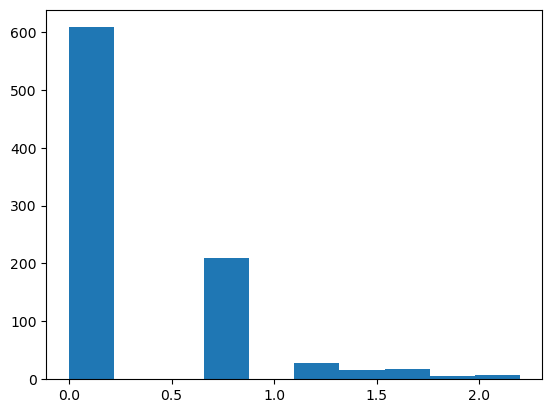

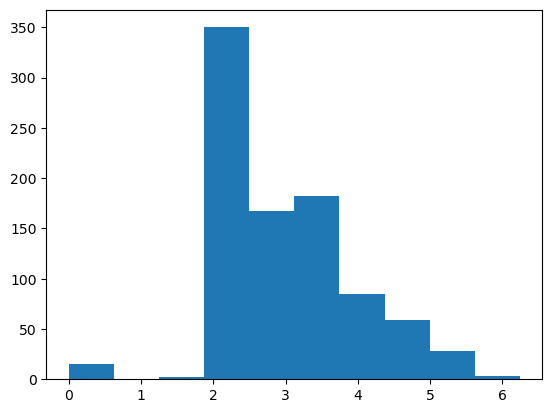

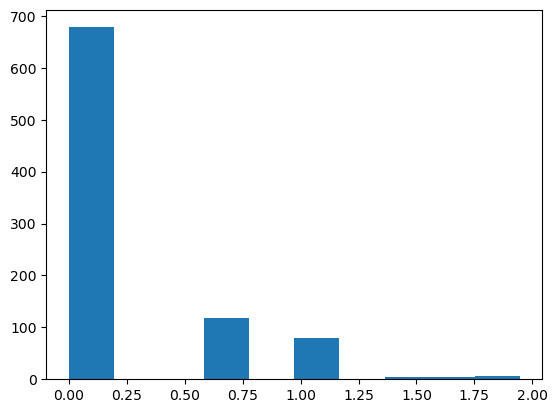

In [230]:
plt.hist(log_norm_sibsp)
plt.show()
plt.hist(log_norm_fare)
plt.show()
plt.hist(log_norm_parch)
plt.show()

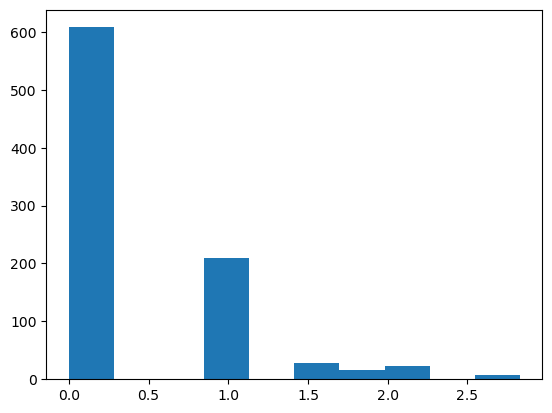

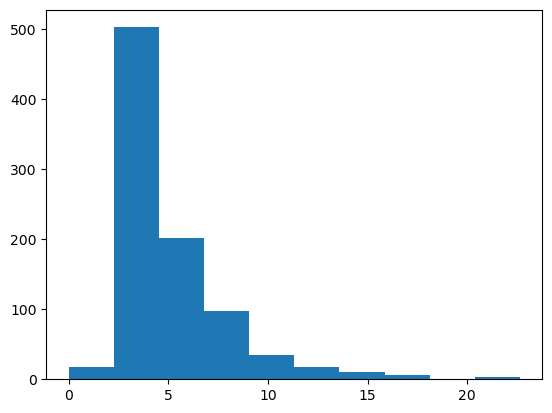

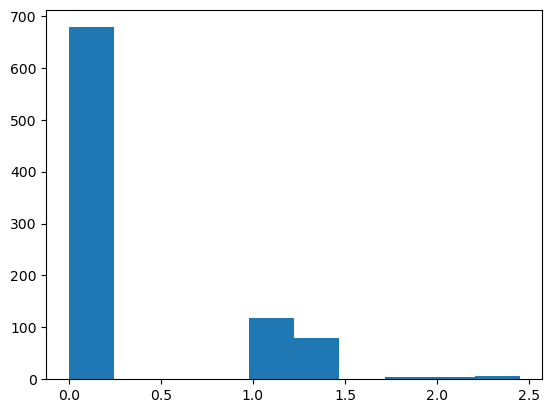

In [231]:
plt.hist(sqrt_norm_sibsp)
plt.show()
plt.hist(sqrt_norm_fare)
plt.show()
plt.hist(sqrt_norm_parch)
plt.show()

In [233]:
# We see that the Most good one is the log transform for the Fare 

In [235]:
# Apply all the previous to all data 

common_subset_Age = all_data[
    (all_data['Pclass'] == 3) & 
    (all_data['SibSp'] == 0) & 
    (all_data['Parch'] == 0) & 
    (all_data['Fare'] <= 24)
]

all_data['num_Cabins'] = all_data.Cabin.apply(lambda x:0 if pd.isna(x) else len(x.split(' ')))
all_data['Cabin_letter'] = all_data.Cabin.apply(lambda x:str(x)[0])
all_data['name_title'] = all_data.Name.apply(lambda x:str(x.split(',')[1].split('.')[0]))
all_data.Age = all_data.Age.fillna(common_subset.Age.mean())
all_data.dropna(subset=['Embarked'],inplace = True)
all_data['norm_Fare'] = np.log1p(all_data.Fare) 

In [236]:
all_data.head()

,train/test,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,num_Cabins,Cabin_letter,name_title,norm_Fare
0,train,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,n,Mr,2.110213
1,train,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,C,Mrs,4.280593
2,train,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,n,Miss,2.188856
3,train,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1,C,Mrs,3.990834
4,train,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,n,Mr,2.202765


In [253]:
# Make the One Hot encoding 
all_data.Pclass = all_data.Pclass.astype(str)
all_dummies = pd.get_dummies(all_data[['Pclass','Sex','Age','SibSp','Parch','norm_Fare','Embarked','Cabin_letter','num_Cabins','name_title']],dtype=int)
all_dummies.head()

,Age,SibSp,Parch,norm_Fare,num_Cabins,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,...,name_title_ Master,name_title_ Miss,name_title_ Mlle,name_title_ Mme,name_title_ Mr,name_title_ Mrs,name_title_ Ms,name_title_ Rev,name_title_ Sir,name_title_ the Countess
0,22.0,1,0,2.110213,0,0,0,1,0,1,...,0,0,0,0,1,0,0,0,0,0
1,38.0,1,0,4.280593,1,1,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
2,26.0,0,0,2.188856,0,0,0,1,1,0,...,0,1,0,0,0,0,0,0,0,0
3,35.0,1,0,3.990834,1,1,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,35.0,0,0,2.202765,0,0,0,1,0,1,...,0,0,0,0,1,0,0,0,0,0


In [254]:
df = pd.concat([all_data.drop(columns=['Pclass','Sex','Age','SibSp','Parch','norm_Fare','Embarked','Cabin_letter','num_Cabins','name_title']),all_dummies],axis = 1)

In [258]:
df.head()

,train/test,PassengerId,Survived,Name,Ticket,Fare,Cabin,Age,SibSp,Parch,...,name_title_ Master,name_title_ Miss,name_title_ Mlle,name_title_ Mme,name_title_ Mr,name_title_ Mrs,name_title_ Ms,name_title_ Rev,name_title_ Sir,name_title_ the Countess
0,train,1,0.0,"Braund, Mr. Owen Harris",A/5 21171,7.2500,NaN,22.0,1,0,...,0,0,0,0,1,0,0,0,0,0
1,train,2,1.0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",PC 17599,71.2833,C85,38.0,1,0,...,0,0,0,0,0,1,0,0,0,0
2,train,3,1.0,"Heikkinen, Miss. Laina",STON/O2. 3101282,7.9250,NaN,26.0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,train,4,1.0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",113803,53.1000,C123,35.0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,train,5,0.0,"Allen, Mr. William Henry",373450,8.0500,NaN,35.0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [264]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 46 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   PassengerId               889 non-null    int64  
 1   Survived                  889 non-null    float64
 2   Name                      889 non-null    object 
 3   Ticket                    889 non-null    object 
 4   Fare                      889 non-null    float64
 5   Cabin                     202 non-null    object 
 6   Age                       889 non-null    float64
 7   SibSp                     889 non-null    int64  
 8   Parch                     889 non-null    int64  
 9   norm_Fare                 889 non-null    float64
 10  num_Cabins                889 non-null    int64  
 11  Pclass_1                  889 non-null    int64  
 12  Pclass_2                  889 non-null    int64  
 13  Pclass_3                  889 non-null    int64  
 14  Sex_female     

In [269]:
# Split the data to train and test

X_train = df[df['train/test'] == 'train'].drop(['train/test'],axis = 1)
X_train.drop(columns=['Name','Ticket','Cabin'],inplace=True)
X_test  = df[df['train/test'] == 'test'].drop(['train/test'],axis = 1)
X_test.drop(columns=['Name','Ticket','Cabin'],inplace=True)
y_train = df[df['train/test'] == 'train'].Survived
y_train.shape

(889,)

In [270]:
X_train.head()

,PassengerId,Survived,Fare,Age,SibSp,Parch,norm_Fare,num_Cabins,Pclass_1,Pclass_2,...,name_title_ Master,name_title_ Miss,name_title_ Mlle,name_title_ Mme,name_title_ Mr,name_title_ Mrs,name_title_ Ms,name_title_ Rev,name_title_ Sir,name_title_ the Countess
0,1,0.0,7.2500,22.0,1,0,2.110213,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,2,1.0,71.2833,38.0,1,0,4.280593,1,1,0,...,0,0,0,0,0,1,0,0,0,0
2,3,1.0,7.9250,26.0,0,0,2.188856,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,4,1.0,53.1000,35.0,1,0,3.990834,1,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,0.0,8.0500,35.0,0,0,2.202765,0,0,0,...,0,0,0,0,1,0,0,0,0,0


## Building the Model

In [285]:
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [271]:
gnb = GaussianNB()
cv = cross_val_score(gnb,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[1. 1. 1. 1. 1.]
1.0


In [272]:
lr = LogisticRegression(max_iter = 2000)
cv = cross_val_score(lr,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[1. 1. 1. 1. 1.]
1.0


In [275]:
dt = tree.DecisionTreeClassifier(random_state = 1)
cv = cross_val_score(dt,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[1. 1. 1. 1. 1.]
1.0


In [276]:
knn = KNeighborsClassifier()
cv = cross_val_score(knn,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[0.62359551 0.45505618 0.47752809 0.47752809 0.68361582]
0.5434647368755158


In [277]:
rf = RandomForestClassifier(random_state = 1)
cv = cross_val_score(rf,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[1. 1. 1. 1. 1.]
1.0


In [280]:
svc = SVC(probability = True)
cv = cross_val_score(svc,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[0.61797753 0.64044944 0.64606742 0.64044944 0.65536723]
0.6400622103726274


In [287]:
xgb = XGBClassifier(random_state =1)
cv = cross_val_score(xgb,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[1. 1. 1. 1. 1.]
1.0


In [288]:
from sklearn.ensemble import VotingClassifier
voting_clf = VotingClassifier(estimators = [('lr',lr),('knn',knn),('rf',rf),('gnb',gnb),('svc',svc),('xgb',xgb)], voting = 'soft') 

In [291]:
cv = cross_val_score(voting_clf,X_train,y_train,cv=5)
print(cv)
print(cv.mean())

[1. 1. 1. 1. 1.]
1.0
